Problem Statement - Emoloyee_attrition

A large corporation is facing high employee turnover and wants to identify factors leading to attrition. The goal is to analyze employee data, including job satisfaction, performance reviews, and compensation. By developing a predictive model, the corporation aims to identify employees at risk of leaving and implement retention strategies, such as career development programs and improved work conditions, to retain top talent.

In [2]:
# impoting all necessary libraries
import pandas as pd
pd.set_option('display.max_columns', None)
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install hvplot
!pip install holoviews
import hvplot.pandas
!pip install --upgrade hvplot holoviews bokeh
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
import joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 3.4 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 52.9 MB/s eta 0:00:00
  Attempting uninstall: bokeh
    Found existing installation: bokeh 3.8.2
    Uninstalling bokeh-3.8.2:
      Successfully uninstalled bokeh-3.8.2


In [4]:
# importing data
data = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")
data

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8


# **Exploratory Data Analysis**

In [5]:
data.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [7]:
data.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [8]:
for column in data.columns:
    print(f"{column}: Number of unique values {data[column].nunique()}")
    print("==========================================================")
#"over18" and "StandardHours", "Employeecount" has only one unique value
#EmployeeCount is 1 and StandardHours is 80 for everyone , Over18 is Y
#we will drop these columns

Age: Number of unique values 43
Attrition: Number of unique values 2
BusinessTravel: Number of unique values 3
DailyRate: Number of unique values 886
Department: Number of unique values 3
DistanceFromHome: Number of unique values 29
Education: Number of unique values 5
EducationField: Number of unique values 6
EmployeeCount: Number of unique values 1
EmployeeNumber: Number of unique values 1470
EnvironmentSatisfaction: Number of unique values 4
Gender: Number of unique values 2
HourlyRate: Number of unique values 71
JobInvolvement: Number of unique values 4
JobLevel: Number of unique values 5
JobRole: Number of unique values 9
JobSatisfaction: Number of unique values 4
MaritalStatus: Number of unique values 3
MonthlyIncome: Number of unique values 1349
MonthlyRate: Number of unique values 1427
NumCompaniesWorked: Number of unique values 10
Over18: Number of unique values 1
OverTime: Number of unique values 2
PercentSalaryHike: Number of unique values 15
PerformanceRating: Number of uni

In [9]:
data.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [10]:
attrition_count = pd.DataFrame(data["Attrition"].value_counts())
attrition_count

,count
Attrition,
No,1233
Yes,237


<Axes: xlabel='Attrition', ylabel='count'>

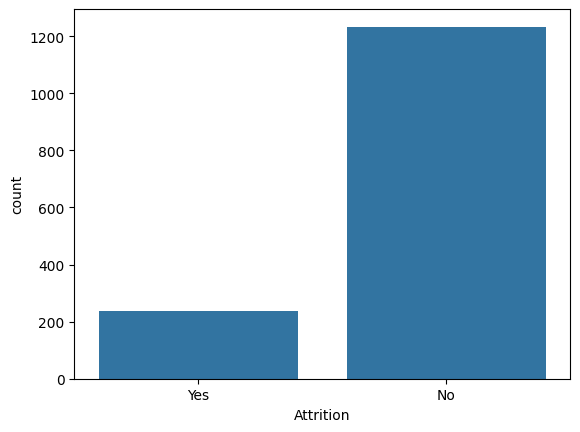

In [11]:
# count for attrition
sns.countplot(x = "Attrition", data = data)

In [12]:
# droping unwanted columns
data.drop(["EmployeeCount","Over18","StandardHours"],axis=1,inplace=True)
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


In [13]:
data.shape

(1470, 32)

In [14]:
# Unique categorical features
object_col = []
for column in data.columns:
    if data[column].dtype == object and len(data[column].unique()) <= 30:
        object_col.append(column)
        print(f"{column} : {data[column].unique()}")
        print(data[column].value_counts())
        print("====================================")


Attrition : ['Yes' 'No']
Attrition
No     1233
Yes     237
Name: count, dtype: int64
BusinessTravel : ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
Department : ['Sales' 'Research & Development' 'Human Resources']
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
EducationField : ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
Gender : ['Female' 'Male']
Gender
Male      882
Female    588
Name: count, dtype: int64
JobRole : ['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representativ

In [15]:
# transformation of attribution column
label = LabelEncoder()
data["Attrition"] = label.fit_transform(data.Attrition)

In [16]:
# Numerical Features
num_col = []
for column in data.columns:
    if data[column].dtype != object and data[column].nunique() < 30:
        print(f"{column} : {data[column].unique()}")
        print("====================================")
        num_col.append(column)


Attrition : [1 0]
DistanceFromHome : [ 1  8  2  3 24 23 27 16 15 26 19 21  5 11  9  7  6 10  4 25 12 18 29 22
 14 20 28 17 13]
Education : [2 1 4 3 5]
EnvironmentSatisfaction : [2 3 4 1]
JobInvolvement : [3 2 4 1]
JobLevel : [2 1 3 4 5]
JobSatisfaction : [4 2 3 1]
NumCompaniesWorked : [8 1 6 9 0 4 5 2 7 3]
PercentSalaryHike : [11 23 15 12 13 20 22 21 17 14 16 18 19 24 25]
PerformanceRating : [3 4]
RelationshipSatisfaction : [1 4 2 3]
StockOptionLevel : [0 1 3 2]
TrainingTimesLastYear : [0 3 2 5 1 4 6]
WorkLifeBalance : [1 3 2 4]
YearsInCurrentRole : [ 4  7  0  2  5  9  8  3  6 13  1 15 14 16 11 10 12 18 17]
YearsSinceLastPromotion : [ 0  1  3  2  7  4  8  6  5 15  9 13 12 10 11 14]
YearsWithCurrManager : [ 5  7  0  2  6  8  3 11 17  1  4 12  9 10 15 13 16 14]


In [17]:
# count in columns for values
count_col = []
for column in data.columns:
  if data[column].dtype != object and data[column].nunique() >30:
    print(f"{column} : Minimum: {data[column].min()}, Maximum: {data[column].max()}")
    count_col.append(column)
    print("==========================================================")

Age : Minimum: 18, Maximum: 60
DailyRate : Minimum: 102, Maximum: 1499
EmployeeNumber : Minimum: 1, Maximum: 2068
HourlyRate : Minimum: 30, Maximum: 100
MonthlyIncome : Minimum: 1009, Maximum: 19999
MonthlyRate : Minimum: 2094, Maximum: 26999
TotalWorkingYears : Minimum: 0, Maximum: 40
YearsAtCompany : Minimum: 0, Maximum: 40


In [18]:
data.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


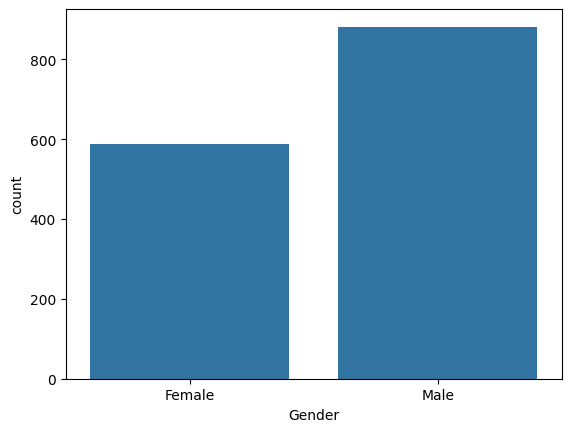

In [19]:
# Data Visulization
# countplot fro gender
sns.countplot(x = "Gender", data= data)
plt.show()

In [20]:
# histogram plot distribution of DistanceFromHome and attrition.
distancefromhome_plot =data.hvplot.hist(y='DistanceFromHome', by='Attrition', subplots=False, width=900, height=500, bins=30)
distancefromhome_plot

# 1. Most employees reside within a 0-5km radius of the workplace, with numbers decreasing as distance grows.
#    Attrition rates are inconsistent across all distance groups

:NdOverlay   [Attrition]
   :Histogram   [DistanceFromHome]   (Count)

In [21]:
# histogram comparing the distribution of education levels with attrition
data.hvplot.hist(y='Education', by='Attrition', subplots=False, width=700, height=350)

# 1. Higher education correlates with lower attrition rates. The majority of employees hold Bachelor's degrees.
#    Targeted retention strategies for less educated employees can help reduce turnover.

:NdOverlay   [Attrition]
   :Histogram   [Education]   (Count)

In [22]:
# histogram comparing the distribution of relationship satisfaction levels with attrition
data.hvplot.hist(y='RelationshipSatisfaction', by='Attrition', subplots=False, width=700, height=350)

#1. Employees with strong work relationships [3,4] tend to stay longer, while those with weaker ones[1,2] are more
#   likely to leave.

:NdOverlay   [Attrition]
   :Histogram   [RelationshipSatisfaction]   (Count)

In [23]:
# histogram of EnvironmentSatisfaction with Attrition
data.hvplot.hist(y='EnvironmentSatisfaction', by='Attrition', subplots=False, width=700, height=350)
#1.  Employees with high environment satisfaction [3,4] are more likely to stay, while those with low satisfaction
#    [1,2] are more prone to leave.

:NdOverlay   [Attrition]
   :Histogram   [EnvironmentSatisfaction]   (Count)

In [24]:
# histogram for JobInvolvement with attrition
data.hvplot.hist(y='JobInvolvement', by='Attrition', subplots=False, width=700, height=350)
#1. Employees with higher job involvement [3,4] tend to stay with the company longer, while those less involved
#   are [1,2] more likely to leave.

:NdOverlay   [Attrition]
   :Histogram   [JobInvolvement]   (Count)

In [25]:
# histogram for joblevel and attrition
data.hvplot.hist(y='JobLevel', by='Attrition', subplots=False, width=700, height=350)
#1. Employees at higher job levels are less likely to leave the company compared to those at lower job levels.
#   This suggests that job level is correlated with employee retention.

:NdOverlay   [Attrition]
   :Histogram   [JobLevel]   (Count)

In [26]:
# histogram for jobsatisfaction with attrition
data.hvplot.hist(y='JobSatisfaction', by='Attrition', subplots=False, width=700, height=350)
#1. Job satisfaction increases, the proportion of employees who leave the company decreases.
#   This indicates a strong correlation between higher job satisfaction and lower attrition rates.

:NdOverlay   [Attrition]
   :Histogram   [JobSatisfaction]   (Count)

In [27]:
# histogram for relationship between No of companied worked and attrition
data.hvplot.hist(y='NumCompaniesWorked', by='Attrition', subplots=False, width=700, height=350)
# As the number of companies worked for increases, the proportion of employees who leave the company also increases.
# This indicates a potential correlation between job hopping and higher attrition rates.

:NdOverlay   [Attrition]
   :Histogram   [NumCompaniesWorked]   (Count)

In [28]:
# histogram for relationship bewteen PercentSalaryHike and attrition
data.hvplot.hist(y='PercentSalaryHike', by='Attrition', subplots=False, width=700, height=350)
# Employees who received higher salary hikes (16-20%) are less likely to leave the company compared to those
# with lower salary hikes (12-14%).

:NdOverlay   [Attrition]
   :Histogram   [PercentSalaryHike]   (Count)

In [29]:
# histogram for relationship bewteen StockOptionLevel and attrition
data.hvplot.hist(y='StockOptionLevel', by='Attrition', subplots=False, width=700, height=350)
# Employees with higher stock option levels (2.5 and 3) are less likely to leave the company compared to those
# with lower stock option levels (0.5 and 1).

:NdOverlay   [Attrition]
   :Histogram   [StockOptionLevel]   (Count)

In [30]:
# histogram for relationship bewteen TrainingTimeLastyear and attrition
data.hvplot.hist(y='TrainingTimesLastYear', by='Attrition', subplots=False, width=700, height=350)
# Employees with higher training time last year 3-4 are less likely to leave the company compared to
# those with lower training time last year 0-1.

:NdOverlay   [Attrition]
   :Histogram   [TrainingTimesLastYear]   (Count)

In [31]:
# histogram for relationship bewteen Age and attrition
data.hvplot.hist(y='Age', by='Attrition', subplots=False, width=700, height=350, bins=35)
# There's a general trend of higher attrition among younger employees

:NdOverlay   [Attrition]
   :Histogram   [Age]   (Count)

In [32]:
# histogram for relationship bewteen MonthlyIncome and attrition
data.hvplot.hist(y='MonthlyIncome', by='Attrition', subplots=False, width=700, height=350, bins=50)
# Employees with higher monthly incomes tend to have lower attrition rates compared to those with lower incomes.

:NdOverlay   [Attrition]
   :Histogram   [MonthlyIncome]   (Count)

In [33]:
# histogram for relationship bewteen YearsAtCompany and attrition
data.hvplot.hist(y='YearsAtCompany', by='Attrition', subplots=False, width=700, height=350, bins=35)
# Employees with fewer years at the company tend to have higher attrition rates compared to those with more tenure.

:NdOverlay   [Attrition]
   :Histogram   [YearsAtCompany]   (Count)

In [34]:
# histogram for relationship bewteen TotalWorkingYears and attrition
data.hvplot.hist(y='TotalWorkingYears', by='Attrition', subplots=False, width=700, height=350, bins=35)
# Employees with fewer total working years tend to have higher attrition rates compared to those with more experience.

:NdOverlay   [Attrition]
   :Histogram   [TotalWorkingYears]   (Count)

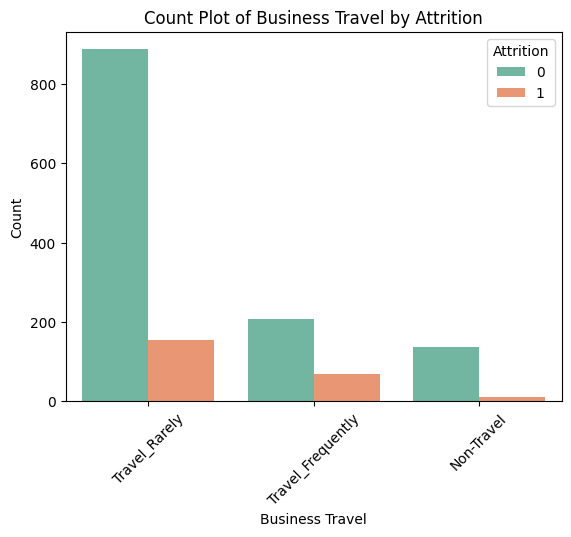

In [35]:
# Count Plot for relationship bewteen BusinessTravel and attrition
sns.countplot(data=data, x='BusinessTravel', hue='Attrition', palette='Set2')
plt.title('Count Plot of Business Travel by Attrition')
plt.xlabel('Business Travel')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()
# The employess who travel alot are more likely to quit then other employees.

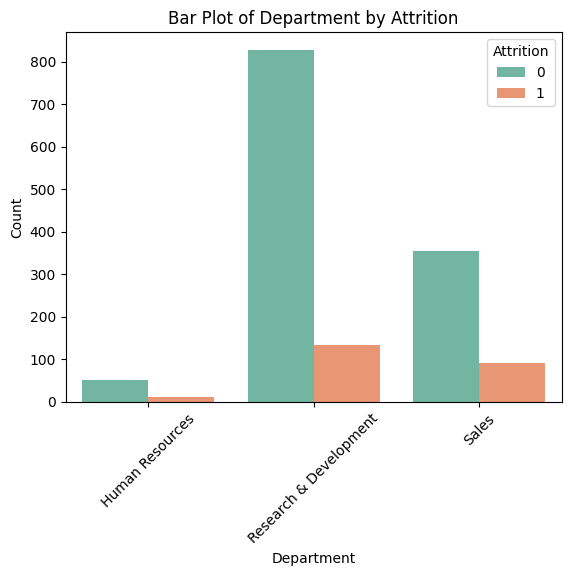

In [36]:
# Bar Plot for relationship bewteen Department and attrition
bar_data = data.groupby(['Department', 'Attrition']).size().reset_index(name='Count')
sns.barplot(data=bar_data, x='Department', y='Count', hue='Attrition', palette='Set2')
plt.title('Bar Plot of Department by Attrition')
plt.xlabel('Department')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()
# The employees in Human resources & Sales are more likely to quit than the employess on Resarch & Development departement.

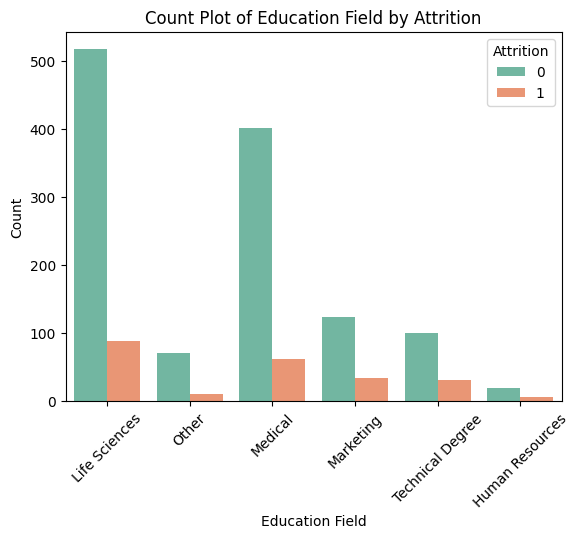

In [37]:
# Count Plot for relationship bewteen EducationField and attrition
sns.countplot(data=data, x='EducationField', hue='Attrition', palette='Set2')
plt.title('Count Plot of Education Field by Attrition')
plt.xlabel('Education Field')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()
# The employess with Human Resources and Technical Degree are more likely to quit then employees from other
# fields of educations.

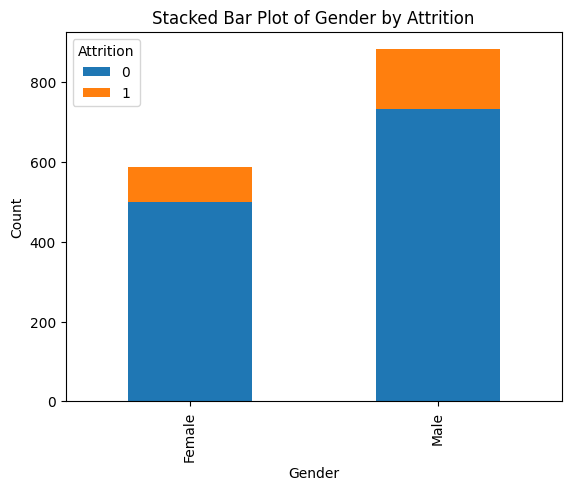

In [38]:
# stacked bar for relationship between Gender and attrition
counts = data.groupby(['Gender', 'Attrition']).size().unstack().fillna(0)
counts.plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'])
plt.title('Stacked Bar Plot of Gender by Attrition')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Attrition')
plt.show()
# Males are more likely to quit.

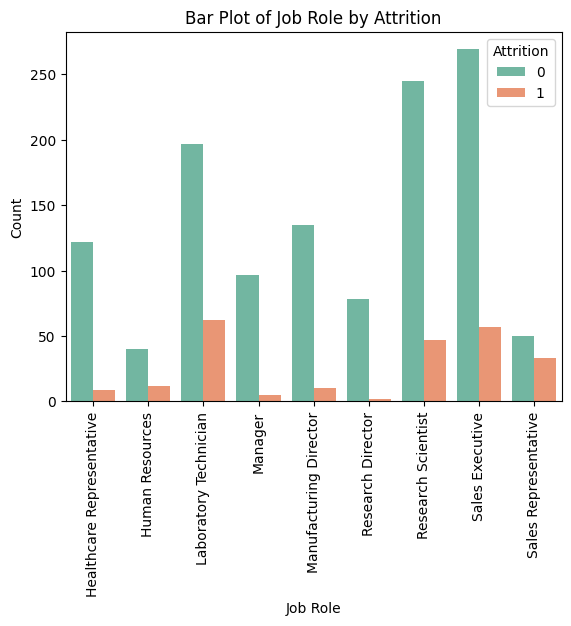

In [39]:
# staked bar for relationship between jobrole and attrition
bar_data = data.groupby(['JobRole', 'Attrition']).size().reset_index(name='Count')
sns.barplot(data=bar_data, x='JobRole', y='Count', hue='Attrition', palette='Set2')
plt.title('Bar Plot of Job Role by Attrition')
plt.xlabel('Job Role')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()
# The employees in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit than
# employees in other positions.

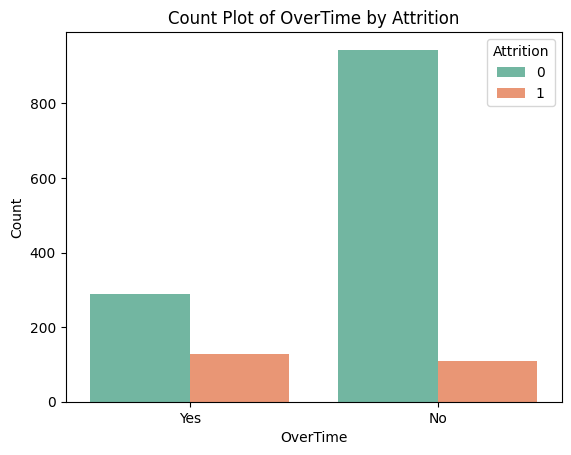

In [40]:
# Count Plot for relationshio of OverTime with attrition
sns.countplot(data=data, x='OverTime', hue='Attrition', palette='Set2')
plt.title('Count Plot of OverTime by Attrition')
plt.xlabel('OverTime')
plt.ylabel('Count')
plt.show()

# The employee who work more hours are likely to quit then others.

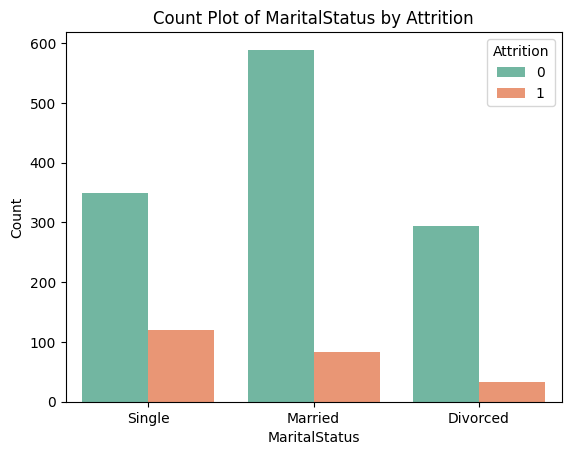

In [41]:
# Count Plot for relationshio of MaritalStatus with attrition
sns.countplot(data=data, x='MaritalStatus', hue='Attrition', palette='Set2')
plt.title('Count Plot of MaritalStatus by Attrition')
plt.xlabel('MaritalStatus')
plt.ylabel('Count')
plt.show()
# The employees who have Single marital status are more likely to quit the Married, and Divorced.

In [42]:
"""
The employees with low JobLevel, MonthlyIncome, YearAtCompany, and TotalWorkingYears, HigherSalaryHiks are more likely to quit there jobs.

EnvironmentSatisfaction, JobSatisfaction incresses the attrition rate decreses.

BusinessTravel : The employess who travel alot are more likely to quit then other employees.

Age: There's a general trend of higher attrition among younger employees.

Department : The employees in Human resources & Sales are more likely to quit than the employess on Resarch & Development departement.

Job role: The employees in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit.

EducationField : The employees with Human Resources and Technical Degree are more likely to quit than employees from other fields of educations.

Gender : The Male are more likely to quit.

JobRole : The employees in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit the employees in other positions.

MaritalStatus : The employees who have Single marital status are more likely to quit the Married, and Divorced.

OverTime : The employees who work more hours are likely to quit then others.



"""

"\nThe employees with low JobLevel, MonthlyIncome, YearAtCompany, and TotalWorkingYears, HigherSalaryHiks are more likely to quit there jobs.\n\nEnvironmentSatisfaction, JobSatisfaction incresses the attrition rate decreses.\n\nBusinessTravel : The employess who travel alot are more likely to quit then other employees.\n\nAge: There's a general trend of higher attrition among younger employees.\n\nDepartment : The employees in Human resources & Sales are more likely to quit than the employess on Resarch & Development departement.\n\nJob role: The employees in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit.\n\nEducationField : The employees with Human Resources and Technical Degree are more likely to quit than employees from other fields of educations.\n\nGender : The Male are more likely to quit.\n\nJobRole : The employees in Laboratory Technician, Sales Representative, and Human Resources are more likely to quit the employees in other position

# **Data processing**

In [43]:
# Converting all categorical features into dummy vairabels
categorical_columns = data.select_dtypes(include=['object']).columns

# Convert all categorical columns to dummy variables
data = pd.get_dummies(data, columns=categorical_columns, drop_first=True, dtype='uint8')

# Check the new dataframe info
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 46 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Age                                1470 non-null   int64
 1   Attrition                          1470 non-null   int64
 2   DailyRate                          1470 non-null   int64
 3   DistanceFromHome                   1470 non-null   int64
 4   Education                          1470 non-null   int64
 5   EmployeeNumber                     1470 non-null   int64
 6   EnvironmentSatisfaction            1470 non-null   int64
 7   HourlyRate                         1470 non-null   int64
 8   JobInvolvement                     1470 non-null   int64
 9   JobLevel                           1470 non-null   int64
 10  JobSatisfaction                    1470 non-null   int64
 11  MonthlyIncome                      1470 non-null   int64
 12  MonthlyRate         

In [44]:
print(data.shape)

# Removing duplicate Features
data = data.T.drop_duplicates()
data = data.T

# Removing Duplicate Rows
data.drop_duplicates(inplace=True)

print(data.shape)

(1470, 46)
(1470, 46)


In [45]:
# spliting data into feature and target  & train and test set

X = data.drop('Attrition', axis=1)
y = data.Attrition

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [47]:
# Hyperparameter tuning for Random Forest
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}

grid_search_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid=param_grid_rf, cv=5, scoring='f1')
grid_search_rf.fit(X_train, y_train)

# Best parameters for Random Forest
best_rf = grid_search_rf.best_estimator_

# Predictions with Random Forest
y_pred_rf = best_rf.predict(X_test)

# Train and Test Accuracy for Random Forest
train_accuracy_rf = best_rf.score(X_train, y_train)
test_accuracy_rf = best_rf.score(X_test, y_test)

print("Random Forest Train Accuracy: ", train_accuracy_rf)
print("Random Forest Test Accuracy: ", test_accuracy_rf)

# Classification report and Confusion Matrix for Random Forest
print("Classification Report for Random Forest:\n", classification_report(y_test, y_pred_rf))

Random Forest Train Accuracy:  0.9970845481049563
Random Forest Test Accuracy:  0.8571428571428571
Classification Report for Random Forest:
               precision    recall  f1-score   support

           0       0.87      0.98      0.92       380
           1       0.43      0.10      0.16        61

    accuracy                           0.86       441
   macro avg       0.65      0.54      0.54       441
weighted avg       0.81      0.86      0.82       441



In [48]:
# Applying SMOTE to training data for Gradient Boosting Classifier
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# Initializing and fiting Gradient Boosting Classifier
gbc = GradientBoostingClassifier(random_state=42)
gbc.fit(X_train_sm, y_train_sm)

# Predictions with Gradient Boosting Classifier
y_pred_gbc = gbc.predict(X_test)

# Train and Test Accuracy for Gradient Boosting Classifier
train_accuracy_gbc = gbc.score(X_train_sm, y_train_sm)
test_accuracy_gbc = gbc.score(X_test, y_test)

print("Gradient Boosting Classifier Train Accuracy: ", train_accuracy_gbc)
print("Gradient Boosting Classifier Test Accuracy: ", test_accuracy_gbc)

# Classification report and Confusion Matrix for Gradient Boosting Classifier
print("Classification Report for Gradient Boosting Classifier:\n", classification_report(y_test, y_pred_gbc))

Gradient Boosting Classifier Train Accuracy:  0.9671746776084408
Gradient Boosting Classifier Test Accuracy:  0.8594104308390023
Classification Report for Gradient Boosting Classifier:
               precision    recall  f1-score   support

           0       0.90      0.94      0.92       380
           1       0.49      0.38      0.43        61

    accuracy                           0.86       441
   macro avg       0.70      0.66      0.67       441
weighted avg       0.85      0.86      0.85       441



In [49]:
# Saving the Gradient Boosting Model
joblib.dump(gbc, 'gradient_boosting_model.pkl')
print("Gradient Boosting Model saved successfully.")

Gradient Boosting Model saved successfully.


In [50]:
# Loading the Gradient Boosting Model
#When we need to use the model in the future, we can load it as follows

loaded_model = joblib.load('gradient_boosting_model.pkl')
print("Gradient Boosting Model loaded successfully.")

Gradient Boosting Model loaded successfully.


In [51]:
# Making predictions on the entire dataset
y_final_pred = loaded_model.predict(X)

# Adding predictions to the dataset
final_dataset = X.copy()
final_dataset['Predicted_Attrition'] = y_final_pred

# Save the final dataset
final_dataset.to_csv('final_dataset_with_predictions.csv', index=False)
print("Final dataset with predictions saved successfully.")

Final dataset with predictions saved successfully.
